# 04 — Background robustness and feature diagnostics

Replaces obsolete window/ranking/NMS diagnostics with paired mask-versus-full-crop analysis. The original filename is retained.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

LOCAL = Path('/Users/yingying/Downloads/midterm-csc74030-main')
COLAB = Path('/content/drive/MyDrive/ComputerVision/Midterm/midterm-csc74030-main')
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents, LOCAL, COLAB]
                if (p/'vistas_templates/templates.csv').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set PROJECT to the folder containing vistas_templates.')
DATA = PROJECT/'vistas_templates'
RESULTS = PROJECT/'intensity_results/vistas_global'
CLASSES = ('cone', 'sign')
FEATURES = (
    'Histogram', 'Mean', 'Median', 'Mode', 'Variance',
    'Std / RMS contrast', 'Trimmed mean', 'Entropy', 'Gray-range fraction',
    'Entropy × Contrast', 'Normalized contrast', 'Spatial entropy difference',
)
VIEWS = ('mask', 'crop')
SEED = 42
VERSION = 'global-mask-crop-v1'


def read_manifest():
    """Validate crop identity and source separation before extracting features."""
    table = pd.read_csv(DATA/'templates.csv')
    required = {'crop', 'mask', 'class', 'role', 'source_key'}
    if not required.issubset(table.columns):
        raise ValueError(f'Missing columns: {required-set(table.columns)}')
    if table.crop.duplicated().any():
        raise ValueError('Duplicate crop paths.')
    if not table['class'].isin(CLASSES).all():
        raise ValueError('Only cone and sign are supported.')
    if not table.role.isin(['template', 'validation']).all():
        raise ValueError('Unexpected data role.')
    role_sources = table.groupby('source_key').role.nunique()
    if (role_sources > 1).any():
        raise ValueError('A source image occurs in both template and validation roles.')
    return table


def split_sources(table):
    """Use only template-role sources for reference fitting and calibration."""
    rng = np.random.default_rng(SEED)
    calibration_sources = set()
    for cls in CLASSES:
        sources = np.array(sorted(table.loc[
            (table.role == 'template') & (table['class'] == cls), 'source_key'].unique()))
        if len(sources) < 2:
            raise ValueError(f'Not enough template sources for {cls}.')
        rng.shuffle(sources)
        calibration_sources.update(sources[:max(1, int(len(sources)*.25))])
    table = table.copy()
    table['usage'] = np.where(
        table.role == 'validation', 'held_out',
        np.where(table.source_key.isin(calibration_sources), 'calibration', 'reference'))
    if (table.groupby('source_key').usage.nunique() != 1).any():
        raise ValueError('Source leakage between splits.')
    for usage in ('reference', 'calibration', 'held_out'):
        for cls in CLASSES:
            if not ((table.usage == usage) & (table['class'] == cls)).any():
                raise ValueError(f'Empty split: {usage}/{cls}.')
    return table


def load_crop(row):
    """Convert RGB to 8-bit grayscale BEFORE applying the object mask."""
    with Image.open(DATA/row['crop']) as image:
        gray = np.array(image.convert('L'))
    with Image.open(DATA/row['mask']) as image:
        mask = np.array(image.convert('L')) > 0
    if gray.shape != mask.shape or not mask.any():
        raise ValueError(f"Invalid mask: {row['crop']}")
    return gray, mask


def histogram(pixels):
    counts = np.bincount(np.asarray(pixels).ravel(), minlength=256)
    if counts.sum() == 0:
        raise ValueError('Cannot describe an empty region.')
    return counts.astype(float)/counts.sum()


def entropy(pixels):
    p = histogram(pixels)
    nonzero = p[p > 0]
    return float(-(nonzero*np.log2(nonzero)).sum())


def extract_features(gray, region):
    """One vector per object: mask pixels or all crop pixels; no windows."""
    pixels = gray[region]
    if not pixels.size:
        raise ValueError('Empty computation region.')
    p = histogram(pixels)
    values = pixels.astype(float)
    mean = float(values.mean())
    variance = float(values.var())  # population variance, ddof=0
    std = float(np.sqrt(variance))
    ordered = np.sort(values)
    cut = int(np.floor(.10*len(ordered)))
    trimmed = ordered[cut:len(ordered)-cut] if cut else ordered
    h = entropy(pixels)
    middle = gray.shape[0]//2
    top = gray[:middle][region[:middle]]
    bottom = gray[middle:][region[middle:]]
    # Spatial entropy is undefined when either half contains no selected pixels.
    spatial = abs(entropy(top)-entropy(bottom)) if top.size and bottom.size else np.nan
    return {
        'Histogram': p,
        'Mean': mean,
        'Median': float(np.median(values)),
        'Mode': float(np.argmax(p)),  # lowest gray value wins an exact tie
        'Variance': variance,
        'Std / RMS contrast': std,
        'Trimmed mean': float(trimmed.mean()),
        'Entropy': h,
        'Gray-range fraction': float(p[64:193].sum()),  # inclusive [64, 192]
        'Entropy × Contrast': h*std,
        'Normalized contrast': std/(mean+1.),
        'Spatial entropy difference': spatial,
    }


def input_fingerprint(table):
    """Invalidate results if the manifest, crop/mask contents or code change."""
    digest = hashlib.sha256(VERSION.encode())
    digest.update((DATA/'templates.csv').read_bytes())
    for _, row in table.sort_values('crop').iterrows():
        for column in ('crop', 'mask'):
            digest.update(row[column].encode())
            digest.update((DATA/row[column]).read_bytes())
    return digest.hexdigest()


def build_feature_table(table):
    rows = []
    for _, row in table.iterrows():
        gray, mask = load_crop(row)
        base = {k: row[k] for k in ('crop', 'class', 'source_key', 'role', 'usage')}
        base.update(width=gray.shape[1], height=gray.shape[0],
                    object_pixels=int(mask.sum()),
                    background_fraction=float(1-mask.mean()))
        for view, region in [('mask', mask), ('crop', np.ones_like(mask))]:
            values = extract_features(gray, region)
            for feature in FEATURES:
                vector = np.atleast_1d(values[feature]).astype(float)
                rows.append(dict(base, view=view, feature=feature,
                                 valid=bool(np.isfinite(vector).all()),
                                 value=json.dumps(vector.tolist())))
    return pd.DataFrame(rows)


def matrix(rows):
    return np.array([json.loads(value) for value in rows.value], dtype=float)


def source_weights(rows):
    """Equal total weight per source image within each true class."""
    counts = rows.groupby(['class', 'source_key']).crop.transform('size')
    return 1./counts.to_numpy(dtype=float)


def fit_references(features):
    """Always fit clean, mask-only references; background is never a template."""
    model = {}
    for feature in FEATURES:
        subset = features[(features.usage == 'reference') &
                          (features.view == 'mask') & (features.feature == feature) & features.valid]
        model[feature] = {}
        for cls in CLASSES:
            rows = subset[subset['class'] == cls]
            if rows.empty:
                raise ValueError(f'No valid reference for {cls}/{feature}.')
            vector = np.average(matrix(rows), axis=0, weights=source_weights(rows))
            model[feature][cls] = vector.tolist()
    return model


def class_margin(rows, model, feature, cls):
    """Positive = closer to this class; references are fitted on clean objects."""
    values = matrix(rows)
    other = next(c for c in CLASSES if c != cls)
    own = np.array(model[feature][cls])
    opposite = np.array(model[feature][other])
    def distance(reference):
        if feature == 'Histogram':
            # Slide's max-denominator histogram distance; 0/0 contributes zero.
            return ((values-reference)**2/np.maximum(np.maximum(values, reference), 1e-30)).sum(1)
        return np.abs(values-reference).sum(1)
    return distance(opposite)-distance(own)


def classification_metrics(rows, scores, cls, threshold):
    truth = rows['class'].to_numpy() == cls
    predicted = scores >= threshold
    weights = source_weights(rows)
    positive = weights[truth].sum()
    negative = weights[~truth].sum()
    tpr = float(weights[truth & predicted].sum()/positive) if positive else np.nan
    tnr = float(weights[~truth & ~predicted].sum()/negative) if negative else np.nan
    tp = int(np.sum(truth & predicted)); fp = int(np.sum(~truth & predicted))
    fn = int(np.sum(truth & ~predicted)); tn = int(np.sum(~truth & ~predicted))
    precision = tp/(tp+fp) if tp+fp else 0.
    recall = tp/(tp+fn) if tp+fn else 0.
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.
    return dict(balanced_accuracy=(tpr+tnr)/2, source_weighted_tpr=tpr,
                source_weighted_tnr=tnr, precision=precision, recall=recall, f1=f1,
                tp=tp, fp=fp, fn=fn, tn=tn, evaluated=len(rows))


def threshold_candidates(scores):
    values = np.unique(scores)
    midpoints = values[:-1]+(values[1:]-values[:-1])/2
    return np.r_[np.nextafter(values[0], -np.inf), midpoints,
                 np.nextafter(values[-1], np.inf), 0.]


def evaluate_methods(features, model):
    """Freeze thresholds and winners on background-containing calibration crops."""
    thresholds = {}; curves = []; report = []
    for cls in CLASSES:
        thresholds[cls] = {}
        for feature in FEATURES:
            cal = features[(features.usage == 'calibration') & (features.view == 'crop') &
                           (features.feature == feature) & features.valid]
            scores = class_margin(cal, model, feature, cls)
            candidates = []
            for threshold in threshold_candidates(scores):
                result = classification_metrics(cal, scores, cls, float(threshold))
                item = dict(cls=cls, feature=feature, threshold=float(threshold), **result)
                candidates.append(item); curves.append(item)
            # Fixed tie rule; never consult held-out data when choosing a threshold.
            best = max(candidates, key=lambda r: (r['balanced_accuracy'], -abs(r['threshold']), -r['threshold']))
            thresholds[cls][feature] = best['threshold']
            for usage in ('calibration', 'held_out'):
                for view in VIEWS:
                    all_rows = features[(features.usage == usage) & (features.view == view) &
                                        (features.feature == feature)]
                    rows = all_rows[all_rows.valid]
                    result = classification_metrics(rows, class_margin(rows, model, feature, cls),
                                                    cls, best['threshold'])
                    report.append(dict(cls=cls, feature=feature, usage=usage, view=view,
                                       threshold=best['threshold'], excluded=len(all_rows)-len(rows), **result))
    report = pd.DataFrame(report)
    winners = {}
    for cls in CLASSES:
        cal = report[(report.cls == cls) & (report.usage == 'calibration') & (report.view == 'crop')]
        # Stable order in FEATURES resolves equal calibration scores.
        best = cal.sort_values('balanced_accuracy', ascending=False, kind='stable').iloc[0]
        winners[cls] = dict(feature=best.feature, threshold=float(best.threshold),
                            calibration_balanced_accuracy=float(best.balanced_accuracy))
    return report, thresholds, winners, pd.DataFrame(curves)


def descriptive_table(features):
    """All 11 scalars; each of the 256 histogram bins is exported separately."""
    rows = features[(features.feature != 'Histogram') & features.valid].copy()
    rows['statistic'] = rows.value.map(lambda s: json.loads(s)[0])
    return rows.groupby(['class', 'usage', 'view', 'feature']).statistic.agg(
        ['count', 'mean', 'std', 'min', 'median', 'max']).reset_index()


def run_analysis(force=False):
    table = split_sources(read_manifest())
    fingerprint = input_fingerprint(table)
    metadata_path = RESULTS/'run.json'
    if metadata_path.is_file() and not force:
        metadata = json.loads(metadata_path.read_text())
        if metadata.get('fingerprint') == fingerprint:
            return metadata
    RESULTS.mkdir(parents=True, exist_ok=True)
    features = build_feature_table(table)
    model = fit_references(features)
    report, thresholds, winners, curves = evaluate_methods(features, model)
    table.to_csv(RESULTS/'split_manifest.csv', index=False)
    features.to_csv(RESULTS/'object_features.csv', index=False)
    descriptive_table(features).to_csv(RESULTS/'statistics_summary.csv', index=False)
    report.to_csv(RESULTS/'all_method_scores.csv', index=False)
    curves.to_csv(RESULTS/'calibration_thresholds.csv', index=False)
    (RESULTS/'model.json').write_text(json.dumps(dict(references=model, thresholds=thresholds), indent=2))
    (RESULTS/'winners.json').write_text(json.dumps(winners, indent=2))
    for cls in CLASSES:
        folder = RESULTS/cls
        folder.mkdir(exist_ok=True)
        features[features['class'] == cls].to_csv(folder/'object_features.csv', index=False)
        report[report.cls == cls].to_csv(folder/'method_scores.csv', index=False)
        hist = features[(features['class'] == cls) & (features.feature == 'Histogram')]
        bins = pd.DataFrame(matrix(hist), columns=[f'gray_{i}' for i in range(256)])
        pd.concat([hist[['crop', 'source_key', 'usage', 'view']].reset_index(drop=True), bins], axis=1).to_csv(
            folder/'histograms.csv', index=False)
    metadata = dict(version=VERSION, fingerprint=fingerprint, winners=winners,
                    splits=table.groupby(['usage', 'class']).size().rename('count').reset_index().to_dict('records'),
                    selection='Highest source-balanced accuracy on complete-crop calibration data; ties use declared feature order.',
                    target='Per-class recognition of supplied cone/sign object crops, not background rejection or localization.')
    metadata_path.write_text(json.dumps(metadata, indent=2))
    return metadata


def load_results():
    metadata = run_analysis()
    features = pd.read_csv(RESULTS/'object_features.csv')
    scores = pd.read_csv(RESULTS/'all_method_scores.csv')
    descriptive = pd.read_csv(RESULTS/'statistics_summary.csv')
    return metadata, features, scores, descriptive


def show_scores(scores, cls):
    rows = scores[(scores.cls == cls) & (scores.usage == 'held_out')]
    table = rows.pivot(index='feature', columns='view', values='balanced_accuracy').reindex(FEATURES)
    table['crop_minus_mask'] = table['crop']-table['mask']
    display(table.round(4))
    table[['mask', 'crop']].plot.barh(figsize=(10, 7), xlim=(0, 1), title=f'{cls}: held-out class recognition')
    plt.axvline(.5, color='gray', linestyle='--')
    plt.xlabel('Source-balanced accuracy'); plt.tight_layout(); plt.show()


def predict_crop(image_path, cls):
    """Inference needs an object ROI only: no mask, annotations or window search."""
    if cls not in CLASSES:
        raise ValueError('cls must be cone or sign.')
    if not (RESULTS/'model.json').is_file() or not (RESULTS/'winners.json').is_file():
        raise FileNotFoundError('Run the analysis once before using the frozen classifier.')
    metadata = {'winners': json.loads((RESULTS/'winners.json').read_text())}
    model = json.loads((RESULTS/'model.json').read_text())
    selected = metadata['winners'][cls]
    with Image.open(image_path) as image:
        gray = np.array(image.convert('L'))
    feature = selected['feature']
    vector = np.atleast_1d(extract_features(gray, np.ones_like(gray, dtype=bool))[feature])
    if not np.isfinite(vector).all():
        raise ValueError('Selected feature is undefined for this crop.')
    row = pd.DataFrame([dict(value=json.dumps(vector.tolist()))])
    margin = float(class_margin(row, model['references'], feature, cls)[0])
    return dict(cls=cls, feature=feature, margin=margin, threshold=selected['threshold'],
                accepted=bool(margin >= selected['threshold']))

In [2]:
metadata,features,scores,descriptive=load_results()

## 1. cone — all methods with and without crop background

view,crop,mask,crop_minus_mask
feature,,,
Histogram,0.5764,0.5917,-0.0153
Mean,0.6080,0.6088,-0.0008
Median,0.5509,0.5491,0.0018
Mode,0.4990,0.5860,-0.0870
Variance,0.5911,0.6259,-0.0347
Std / RMS contrast,0.6218,0.6701,-0.0483
Trimmed mean,0.6458,0.6065,0.0393
Entropy,0.6149,0.6638,-0.0489
Gray-range fraction,0.5674,0.5553,0.0122


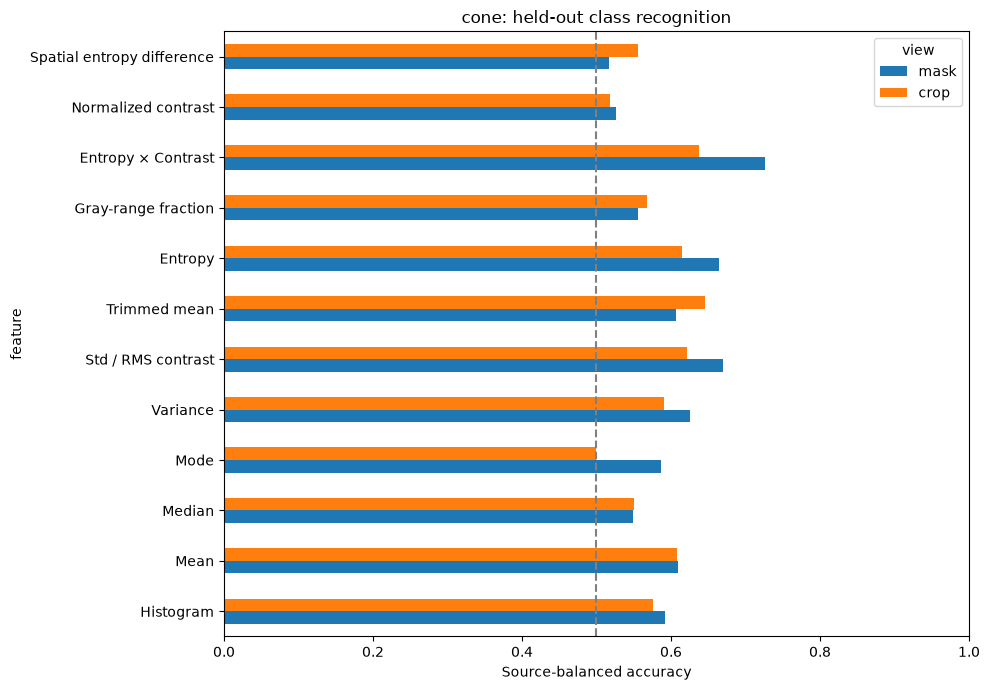

In [3]:
show_scores(scores,'cone')

## 2. sign — all methods with and without crop background

view,crop,mask,crop_minus_mask
feature,,,
Histogram,0.5764,0.5917,-0.0153
Mean,0.6080,0.6088,-0.0008
Median,0.5509,0.5491,0.0018
Mode,0.4990,0.5860,-0.0870
Variance,0.5911,0.6259,-0.0347
Std / RMS contrast,0.6218,0.6701,-0.0483
Trimmed mean,0.6458,0.6065,0.0393
Entropy,0.6149,0.6638,-0.0489
Gray-range fraction,0.5674,0.5553,0.0122


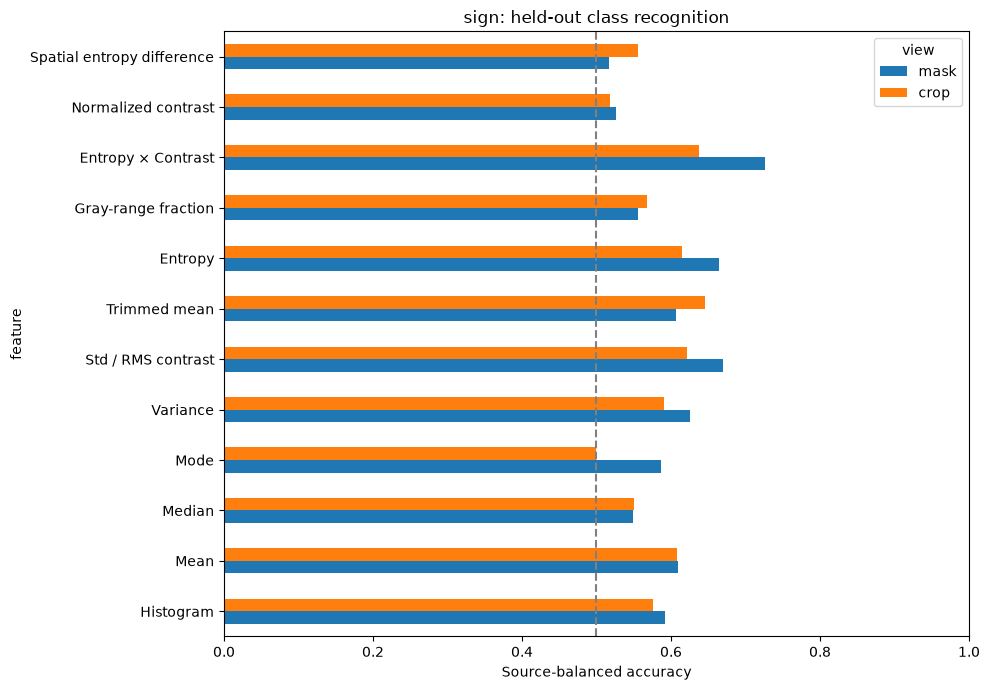

In [4]:
show_scores(scores,'sign')

## 3. Background fraction and recognition of frozen winners

The mask is used only to measure background fraction here; crop features use all pixels. Bins are descriptive subsets of the same held-out data, not additional independent tests.

In [5]:
model=json.loads((RESULTS/'model.json').read_text())
background_rows=[]
for cls in CLASSES:
    selected=metadata['winners'][cls]
    rows=features[(features.usage=='held_out')&(features.view=='crop')&(features.feature==selected['feature'])&features.valid].copy()
    rows['background_bin']=pd.cut(rows.background_fraction,[-.001,.25,.50,.75,1.],labels=['0–25%','25–50%','50–75%','75–100%'])
    for label,subset in rows.groupby('background_bin',observed=True):
        result=classification_metrics(subset,class_margin(subset,model['references'],selected['feature'],cls),cls,selected['threshold'])
        background_rows.append(dict(cls=cls,feature=selected['feature'],background_bin=str(label),**result))
background_report=pd.DataFrame(background_rows)
display(background_report.round(4))
background_report.to_csv(RESULTS/'background_robustness.csv',index=False)

,cls,feature,background_bin,balanced_accuracy,source_weighted_tpr,source_weighted_tnr,precision,recall,f1,tp,fp,fn,tn,evaluated
0,cone,Variance,0–25%,NaN,NaN,0.8000,0.0000,0.0000,0.0000,0,1,0,4,5
1,cone,Variance,25–50%,0.5000,0.4000,0.6000,0.5556,0.4545,0.5000,5,4,6,7,22
2,cone,Variance,50–75%,0.5673,0.6012,0.5333,0.8077,0.6364,0.7119,42,10,24,9,85
3,sign,Variance,0–25%,NaN,0.8000,NaN,1.0000,0.8000,0.8889,4,0,1,0,5
4,sign,Variance,25–50%,0.5000,0.6000,0.4000,0.5385,0.6364,0.5833,7,6,4,5,22
5,sign,Variance,50–75%,0.5673,0.5333,0.6012,0.2727,0.4737,0.3462,9,24,10,42,85


## 4. Paired scalar changes caused by including background

These are raw changes in each feature’s own units; they cannot be compared across features as a universal robustness score.

In [6]:
scalar=features[(features.usage=='held_out')&(features.feature!='Histogram')&features.valid].copy()
scalar['number']=scalar.value.map(lambda x:json.loads(x)[0])
paired=scalar.pivot(index=['crop','class','source_key','feature'],columns='view',values='number').dropna().rename(columns={'crop':'crop_value','mask':'mask_value'}).reset_index()
paired['crop_minus_mask']=paired['crop_value']-paired['mask_value']
paired['absolute_change']=paired.crop_minus_mask.abs()
shift=paired.groupby(['class','feature'])[['crop_minus_mask','absolute_change']].agg(['mean','median','max'])
for cls in CLASSES:
    print(cls);display(shift.loc[cls].round(4))
paired.to_csv(RESULTS/'paired_feature_changes.csv',index=False)

cone


view                       crop_minus_mask                       \
                                      mean    median        max   
feature                                                           
Entropy                             0.3483    0.2513     1.9546   
Entropy × Contrast                 57.1248   36.1228   329.1831   
Gray-range fraction                -0.0493   -0.0344     0.3241   
Mean                              -12.6467  -15.6469    37.4354   
Median                            -12.7403  -11.0000    53.0000   
Mode                              -26.7013   -3.0000   152.0000   
Normalized contrast                 0.1021    0.0636     0.5344   
Spatial entropy difference         -0.0470   -0.0138     0.9373   
Std / RMS contrast                  6.6968    3.8579    42.9312   
Trimmed mean                      -13.1987  -14.9819    40.1926   
Variance                          520.1361  310.1099  4012.9826   

view                       absolute_change                       
                                      mean    median        max  
feature                                                          
Entropy                             0.4216    0.2818     1.9546  
Entropy × Contrast                 72.6471   47.4702   329.1831  
Gray-range fraction                 0.1401    0.1180     0.4654  
Mean                               20.3147   19.5160    52.3930  
Median                             23.1299   21.0000    89.0000  
Mode                               43.7403   15.0000   255.0000  
Normalized contrast                 0.1154    0.0669     0.5344  
Spatial entropy difference          0.3592    0.2505     1.8887  
Std / RMS contrast                  9.0324    5.1797    42.9312  
Trimmed mean                       21.8131   20.4897    57.8665  
Variance                          735.3704  534.6177  4012.9826

sign


view                       crop_minus_mask                       \
                                      mean    median        max   
feature                                                           
Entropy                             0.5922    0.4932     1.6098   
Entropy × Contrast                 81.8761   81.2083   190.7662   
Gray-range fraction                -0.0976   -0.0752     0.0936   
Mean                               -5.7661   -6.5937    40.5795   
Median                             -9.0000   -8.0000    41.0000   
Mode                               -1.8000    0.0000    77.0000   
Normalized contrast                 0.1086    0.0892     0.3568   
Spatial entropy difference         -0.1133   -0.1249     0.4868   
Std / RMS contrast                  9.3113    7.7586    23.3238   
Trimmed mean                       -7.8698   -9.0862    40.9205   
Variance                          696.8695  522.0995  2484.9903   

view                       absolute_change                       
                                      mean    median        max  
feature                                                          
Entropy                             0.5922    0.4932     1.6098  
Entropy × Contrast                 82.1255   81.2083   190.7662  
Gray-range fraction                 0.1114    0.0841     0.4698  
Mean                               12.6168    7.9853    40.5795  
Median                             13.4000   10.0000    41.0000  
Mode                                9.1143    0.0000    77.0000  
Normalized contrast                 0.1101    0.0892     0.3568  
Spatial entropy difference          0.2351    0.2043     0.9012  
Std / RMS contrast                  9.5476    7.7586    23.3238  
Trimmed mean                       13.9666    9.8693    40.9205  
Variance                          713.0027  522.0995  2484.9903

## 5. Undefined feature values and class support

In [7]:
invalid=features[~features.valid]
print('Undefined object/view/feature rows:',len(invalid))
if len(invalid):display(invalid[['crop','class','usage','view','feature']])
display(scores[['cls','feature','usage','view','evaluated','excluded']])

Undefined object/view/feature rows: 0


,cls,feature,usage,view,evaluated,excluded
0,cone,Histogram,calibration,mask,71,0
1,cone,Histogram,calibration,crop,71,0
2,cone,Histogram,held_out,mask,112,0
3,cone,Histogram,held_out,crop,112,0
4,cone,Mean,calibration,mask,71,0
...,...,...,...,...,...,...
91,sign,Normalized contrast,held_out,crop,112,0
92,sign,Spatial entropy difference,calibration,mask,71,0
93,sign,Spatial entropy difference,calibration,crop,71,0
94,sign,Spatial entropy difference,held_out,mask,112,0


## Limits

Background content is limited to original crop rectangles. More distant scene context, pure-background ROIs, imperfect proposals and other object classes require separate frozen-pipeline evaluation. Opposite-class negatives cannot establish background rejection. Small sign calibration support makes method selection uncertain; a winner in this split is not a universal best intensity statistic.